In [ ]:
from google.colab import drive, auth
from google.auth import default
import os, io, json, shutil
from pathlib import Path
import pandas as pd

In [ ]:
drive.mount("/content/drive")
DRIVE = "/content/drive/MyDrive"
PROJECT = f"{DRIVE}/abaya_bot_project"
os.makedirs(PROJECT, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install -q openpyxl pillow

In [ ]:
KB_PATH = f"{DRIVE}/store_info.txt"
CATALOG_PATH = f"{PROJECT}/catalog_full.xlsx"
IMAGES_DIRS = [
    f"{DRIVE}/img",
    f"{DRIVE}/abaya_images"
]
COLUMNS = {
    "code": "product_id",
    "description": "name",
    "price": "price",
    "colors": "colors",
    "sizes": "sizes",
    "fabric": "fabric",
    "image": "photo_file",
    "order_type": "order_type",
    "tailoring_days": "tailoring_days",
    "stock": "stock",
}

In [ ]:
shutil.copy(KB_PATH, f"{PROJECT}/store_info.md")
print(open(f"{PROJECT}/store_info.md", encoding="utf-8-sig").read())

**اسم المتجر:** ايرل  
**اسم البوت:** ايرال بوت  
**العملة:** الدينار البحريني (BHD)  
**اللغة:** اللهجة الخليجية البحرينية  
**خدمة العملاء:** البوت يرد 24 ساعة.

### معلومات المتجر
- المنتجات: عبايات جاهزة وتفصيل.
- الطلبات: عن طريق الإنستقرام والواتساب.
- نطاق الخدمة: البحرين ودول الخليج.

### المنتجات والكتالوج
- الكتالوج: يحتوي على كود واسم وقماش ولون وسعر كل عباية.
- الصور: لكل عباية صور مرتبطة بكودها في الكتالوج.
- التعرف على العباية: يطابق البوت صورة العميلة مع صور الكتالوج. إذا لم يتأكد من العباية، يحول المحادثة للموظفة.
- الألوان والأقمشة والأسعار: تؤخذ من الكتالوج فقط.
- العبايات الجاهزة: التوفر يعتمد على المخزون، والبوت لا يستطيع الاطلاع عليه. يجب التأكد من الموظفة.
- التفصيل: متاح للعبايات الموجودة في الكتالوج.

### المقاسات والتفصيل
- المقاسات: من 50 إلى 60، والمقاس يمثل طول العباية.
- العرض: ستاندر وثابت، ولكل طول قياسات محددة للعرض وطول اليد.
- العرض الخاص: متاح بالطلب في التفصيل بعد التأكد من الموظفة.
- معلومات التفصيل المطلوبة: طول العميلة فقط.
- مدة التفصيل: أسبوع أو

In [ ]:
import io, json, os
from pathlib import Path
import openpyxl
from PIL import Image

def clean(v):
    if v is None:
        return ""
    if isinstance(v, float) and v.is_integer():
        v = int(v)
    return str(v).strip()

# Open the local Excel file directly with openpyxl instead of gspread
wb = openpyxl.load_workbook(CATALOG_PATH, data_only=True)
# If sheet is named 'Catalog', otherwise default to active sheet
ws = wb["Catalog"] if "Catalog" in wb.sheetnames else wb.active

rows = list(ws.iter_rows(values_only=True))
headers = [clean(h) for h in rows[0]]
print("col:", headers)

missing = [v for k, v in COLUMNS.items() if k != "image" and v not in headers]
assert not missing, f"col not found: {missing}"

os.makedirs(f"{PROJECT}/images", exist_ok=True)
extra_cols = [h for h in headers if h and h not in COLUMNS.values()]
catalog = []

for r, line in enumerate(rows[1:], start=2):
    vals = {h: clean(line[i]) if i < len(line) else "" for i, h in enumerate(headers) if h}
    if not any(vals.values()):
        continue
    row = {k: vals.get(v, "") for k, v in COLUMNS.items()}
    code = row["code"] or f"AB{r:03d}"

    data = None
    # Iterate through potential image directories since IMAGES_DIRS is a list
    image_name = row["image"].replace("\u200f", "").replace("\u200e", "").strip()
    for img_dir_str in IMAGES_DIRS:
        d = Path(img_dir_str)
        cands = [d / Path(image_name).name] if image_name else []
        cands += [d / f"{code}.{e}" for e in ("jpg", "jpeg", "png", "webp")]
        for p in cands:
            if p.is_file():
                data = p.read_bytes()
                break
        if data is not None:
            break

    if data is None:
        print(f"⚠️ skip row {r} ({code}): image not found")
        continue

    Image.open(io.BytesIO(data)).convert("RGB").save(
        f"{PROJECT}/images/{code}.jpg", "JPEG", quality=90)

    extras = [f"{h}: {vals[h]}" for h in extra_cols if vals.get(h)]
    desc = " | ".join([x for x in [row["description"]] + extras if x])
    catalog.append({
        "code": code,
        "name": row["description"],
        "price": row["price"],
        "colors": row["colors"],
        "sizes": row["sizes"],
        "fabric": row["fabric"],
        "order_type": row.get("order type", ""),
        "tailoring_days": row["tailoring_days"],
        "stock": row["stock"],
        "description": desc,
        "image": f"{code}.jpg",
    })

json.dump(catalog, open(f"{PROJECT}/catalog.json", "w", encoding="utf-8"),
          ensure_ascii=False, indent=1)

print(f"done {len(catalog)} عباية من أصل {len(rows)-1} صف")
print("img saved:", len(os.listdir(f"{PROJECT}/images")))
print("catalog.json:", os.path.exists(f"{PROJECT}/catalog.json"))

col: ['product_id', 'photo_file', 'name', 'fabric', 'colors', 'price', 'sizes', 'order_type', 'tailoring_days', 'stock', '', '']
done 83 عباية من أصل 83 صف
img saved: 83
catalog.json: True


AYL-095 - عباية بقصة كلوش بقماش نقش الغزال قلبتين
AYL-094 - عباية بقصة ستريت مع فتحات في الجوانب و زيج في الاطراف
AYL-089 - عباية بقصة البليزر الخفيف مع اسفنج في الاكتف
AYL-088 - عباية بقصة ستريت مع دانتيل في الاطراف و من الداخل شيفون
AYL-091 - عباية بقصه بليزر مع دانتيل
AYL-100 - عباية بقصة كلوش
AYL-099 - عباية بقصة كلوش مع زيج
AYL-098 - عباية بقصة كلوش باللون الاسور مع حركة في الجوانب
AYL-097 - عباية بقصة بليزر مبطنة
AYL-096 - عباية بقصة بليزر مبطنة
AYL-093 - عباية مع فتحه في اليد و الجوانب
AYL-092 - عباية بقصة كلوش
AYL-090 - عباية بقصه نص بشت قلبتين
AYL-087 - عباية بقصه بشت مع زيج في الاطراف
AYL-086 - عباية بقصه بشت مع زيج في الاطراف
AYL-085 - عبايه بقصة ستريت بنقش الغزالة
AYL-084 - عباية بقصه البشت مع زيج في الاطراف
AYL-083 - عباية بقصه ستريت مع خرز
AYL-082 - عباية بقصة البشت مع فتحات جانبيه
AYL-081 - عباية بقصة كلوش خفيف مع تطريز في الاطراف
AYL-080 - عباية بقصة ستريت مع فتحات في الجوانب
AYL-079 - عباية بقصه بشت
AYL-078 - عباية بقصه فراشة
AYL-077 - عباية بقصه فراشة
AYL-076 - عباية 

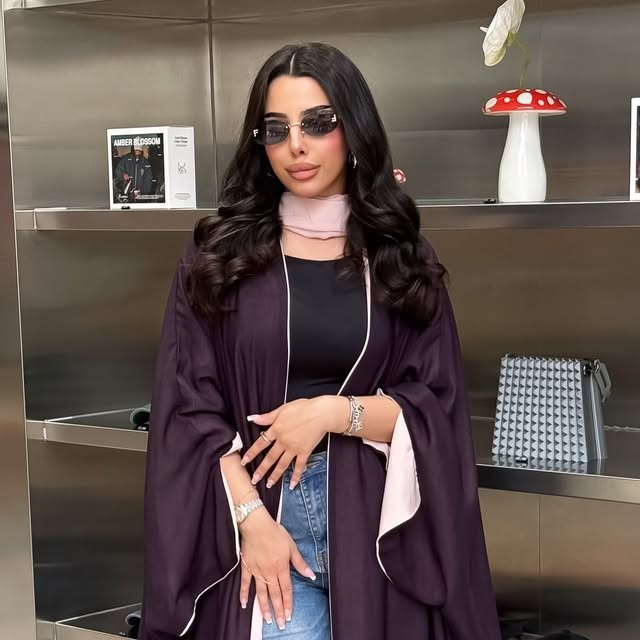

In [ ]:
from IPython.display import display

catalog = json.load(open(f"{PROJECT}/catalog.json", encoding="utf-8"))
for item in catalog:
    print(item["code"], "-", item["name"])

selected_code = input("Enter abaya code: ").strip()
selected = next((i for i in catalog if i["code"] == selected_code), None)

if selected:
    print("Name:", selected["name"])
    print("Price:", selected["price"], "BHD")
    print("Colors:", selected["colors"])
    print("Sizes:", selected["sizes"])
    print("Fabric:", selected["fabric"])
    print("Stock:", selected["stock"])
    display(Image.open(Path(PROJECT) / "images" / selected["image"]))
else:
    print("Abaya not found!")